# Module 2 — Prédiction d'utilité des avis

**Projet ReviewScope** | 8INF867 — Apprentissage automatique | UQAC

---

Ce notebook explore la **prédiction de l'utilité d'un avis Amazon** (`IsHelpful`) à partir de son contenu textuel, de ses signaux stylistiques et de ses métadonnées.  
Il répond à un enjeu clé du cours : la **classification supervisée sur classes déséquilibrées** avec prévention stricte des **fuites de données (data leakage)**.

**Approche supervisée — texte, style et contexte :**
- On filtre uniquement les avis évalués (`HelpfulnessDenominator >= 3`) afin de ne pas confondre absence de votes et inutilité
- On extrait des variables linguistiques et stylistiques (majuscules, ponctuation expressive, lisibilité, lexique mélioratif/péjoratif) avant nettoyage du texte
- On compare 6 familles de modèles et on réalise une **étude d'ablation** pour mesurer l'apport de chaque groupe de features

**Étapes couvertes :**
1. Configuration et imports
2. Chargement et filtrage des avis évalués
3. Découpage temporel anti-fuite (`train ≤ 2010` / `test ≥ 2011`)
4. Extraction des features (TF-IDF + SVD, style/lisibilité, métadonnées produit)
5. Étude d'ablation (apport de chaque famille de variables)
6. Benchmarking des 6 modèles supervisés (PR-AUC, ROC-AUC, F1-macro)
7. Courbes Precision-Recall et matrice de confusion du meilleur modèle
8. Importance des variables (validation des signaux stylistiques)
9. Sauvegarde des résultats et résumé du module

In [ ]:
## 0. Configuration et imports

,Configuration,PR-AUC
0,"1. Métadonnées seules (Note, Produit)",0.7917
1,2. Texte TF-IDF + Style/Lisibilité,0.7740
2,3. Complet (TF-IDF + Style + Métadonnées),0.8290


In [2]:
import sys
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

import config
from src.data_loader import temporal_split, stratified_sample
from src.text_processing import build_tfidf_pipeline, compute_text_features, compute_readability
from src.feature_engineering import compute_metadata_features, build_feature_matrix
from src.models import compare_models

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f"Projet       : {config.PROJECT_ROOT.name}")
print(f"Random state : {config.RANDOM_STATE}")

Projet       : projet_aa
Random state : 42


## 1. Chargement et filtrage des avis évalués

Conformément à l'audit du **Module 0**, les avis avec `HelpfulnessDenominator == 0` ne sont pas des avis inutiles, mais des avis **non évalués**.  
On conserve uniquement les avis ayant reçu au moins `config.MIN_VOTES` (3 votes) et on observe le déséquilibre de la cible `IsHelpful`.

In [3]:
df = pd.read_csv(config.DATA_PROCESSED / 'reviews_clean.csv')
df['DateTime'] = pd.to_datetime(df['Time'], unit='s')

df_eval = df[df['HelpfulnessDenominator'] >= config.MIN_VOTES].copy()

print(f"Avis totaux chargés           : {len(df):,}")
print(f"Avis éligibles (≥ {config.MIN_VOTES} votes)   : {len(df_eval):,} ({len(df_eval)/len(df)*100:.1f}%)")
print(f"  → Utiles (IsHelpful = 1)    : {df_eval['IsHelpful'].sum():,} ({df_eval['IsHelpful'].mean()*100:.1f}%)")
print(f"  → Non-utiles (IsHelpful = 0): {(df_eval['IsHelpful']==0).sum():,} ({(1-df_eval['IsHelpful'].mean())*100:.1f}%)")

Avis totaux chargés           : 393,892
Avis éligibles (≥ 3 votes)   : 88,053 (22.4%)
  → Utiles (IsHelpful = 1)    : 58,826 (66.8%)
  → Non-utiles (IsHelpful = 0): 29,227 (33.2%)


## 2. Échantillonnage stratifié et découpage temporel anti-fuite

On tire un échantillon stratifié représentatif de **25 000 avis** puis on applique un **découpage temporel strict** (`Train ≤ 2010`, `Test ≥ 2011`) afin de reproduire les conditions réelles de mise en production et d'éviter toute fuite temporelle.

In [4]:
sample = stratified_sample(df_eval, n=25000, stratify_col='IsHelpful', random_state=config.RANDOM_STATE)
train_df, test_df = temporal_split(sample, config.TRAIN_END_YEAR, config.TEST_START_YEAR)

assert train_df['Year'].max() <= config.TRAIN_END_YEAR, "Fuite temporelle détectée !"
assert test_df['Year'].min() >= config.TEST_START_YEAR, "Fuite temporelle détectée !"

print(f"Train (≤ {config.TRAIN_END_YEAR}) : {len(train_df):,} avis (Utiles : {train_df['IsHelpful'].mean()*100:.1f}%)")
print(f"Test  (≥ {config.TEST_START_YEAR}) : {len(test_df):,} avis (Utiles : {test_df['IsHelpful'].mean()*100:.1f}%)")
print("✓ Vérification anti-fuite passée : aucune superposition temporelle.")

Train (≤ 2010) : 15,104 avis (Utiles : 70.1%)
Test  (≥ 2011) : 9,896 avis (Utiles : 61.8%)
✓ Vérification anti-fuite passée : aucune superposition temporelle.


## 3. Extraction des features (TF-IDF + SVD, Style, Métadonnées)

Trois familles de variables sont extraites séparément sur le `Train` et le `Test` :
1. **Sémantique (TF-IDF + SVD)** : 30 composantes latentes apprises uniquement sur le `Train`.
2. **Style & Lisibilité** : longueur, ratio de majuscules, ponctuation expressive (`!`, `?`), densité de mots mélioratifs/péjoratifs et indice de lisibilité ARI calculés sur le texte brut.
3. **Métadonnées produit anti-fuite** : note attribuée, polarisation et écart à la moyenne du produit (moyenne calculée exclusivement sur le `Train`).

In [5]:
# 1. TF-IDF + SVD (fit sur train uniquement)
tfidf_svd = build_tfidf_pipeline(max_features=3000, n_components=30)
X_tfidf_tr = tfidf_svd.fit_transform(train_df['Text'].fillna(''))
X_tfidf_te = tfidf_svd.transform(test_df['Text'].fillna(''))

# 2. Features stylistiques et lisibilité
tr_text = compute_text_features(train_df)
te_text = compute_text_features(test_df)
tr_text['readability'] = compute_readability(train_df['Text'])
te_text['readability'] = compute_readability(test_df['Text'])

# 3. Métadonnées sans fuite
tr_meta, prod_means = compute_metadata_features(train_df)
te_meta, _ = compute_metadata_features(test_df, train_product_means=prod_means)

# Assemblage complet
X_train, feat_names = build_feature_matrix(train_df, X_tfidf_tr, None, tr_text, tr_meta)
X_test, _ = build_feature_matrix(test_df, X_tfidf_te, None, te_text, te_meta)

y_train = train_df['IsHelpful'].values
y_test = test_df['IsHelpful'].values

print(f"Matrice X_train : {X_train.shape} ({len(feat_names)} variables)")
print(f"Matrice X_test  : {X_test.shape}")

Matrice X_train : (15104, 50) (50 variables)
Matrice X_test  : (9896, 50)


## 4. Étude d'ablation

Pour quantifier la contribution réelle de chaque groupe de variables, on entraîne un même classifieur (`GradientBoostingClassifier`) sur 4 sous-ensembles progressifs de features et on compare le **PR-AUC** (*Average Precision*).

In [6]:
ablations_tr = {
    "1. Métadonnées seules (Note, Produit)": build_feature_matrix(train_df, None, None, None, tr_meta)[0],
    "2. Style & Lisibilité seuls": build_feature_matrix(train_df, None, None, tr_text, None)[0],
    "3. Texte TF-IDF + Style/Lisibilité": build_feature_matrix(train_df, X_tfidf_tr, None, tr_text, None)[0],
    "4. Complet (TF-IDF + Style + Métadonnées)": X_train,
}
ablations_te = {
    "1. Métadonnées seules (Note, Produit)": build_feature_matrix(test_df, None, None, None, te_meta)[0],
    "2. Style & Lisibilité seuls": build_feature_matrix(test_df, None, None, te_text, None)[0],
    "3. Texte TF-IDF + Style/Lisibilité": build_feature_matrix(test_df, X_tfidf_te, None, te_text, None)[0],
    "4. Complet (TF-IDF + Style + Métadonnées)": X_test,
}

ablation_rows = []
for label in ablations_tr:
    clf = GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=config.RANDOM_STATE)
    clf.fit(ablations_tr[label], y_train)
    proba = clf.predict_proba(ablations_te[label])[:, 1]
    ablation_rows.append({
        "Configuration": label,
        "Nb features": ablations_tr[label].shape[1],
        "PR-AUC (Test)": round(average_precision_score(y_test, proba), 4)
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

,Configuration,Nb features,PR-AUC (Test)
0,"1. Métadonnées seules (Note, Produit)",8,0.7917
1,2. Style & Lisibilité seuls,12,0.7018
2,3. Texte TF-IDF + Style/Lisibilité,42,0.7740
3,4. Complet (TF-IDF + Style + Métadonnées),50,0.8290


## 5. Benchmarking des modèles supervisés

On compare 6 familles d'algorithmes (linéaires, à noyaux, ensemblistes, réseaux de neurones et empilement) sur la matrice complète.  
En raison du déséquilibre de classes, la métrique principale retenue est le **PR-AUC** complétée par le **ROC-AUC** et le **F1-macro**.

In [7]:
results_df, trained_models = compare_models(X_train, y_train, X_test, y_test)
display(results_df)

,Model,PR-AUC,ROC-AUC,F1-macro,F1-helpful,Precision,Recall,Time (s)
0,Stacking,0.8308,0.7716,0.7073,0.7513,0.8122,0.6989,56.82
1,GradientBoosting,0.8288,0.7701,0.7106,0.7777,0.7805,0.7749,23.70
2,LinearSVC,0.8270,0.7668,0.7002,0.7780,0.7640,0.7926,0.37
3,LogisticRegression,0.8263,0.7666,0.7069,0.7516,0.8107,0.7006,0.12
4,RandomForest,0.8257,0.7632,0.7075,0.7559,0.8050,0.7125,1.41
5,MLP,0.8242,0.7657,0.7008,0.7829,0.7603,0.8068,0.63


## 6. Courbes Precision-Recall et matrice de confusion

Visualisation comparative des courbes **Precision-Recall** pour les 6 modèles et analyse de la matrice de confusion du modèle arrivant en tête.

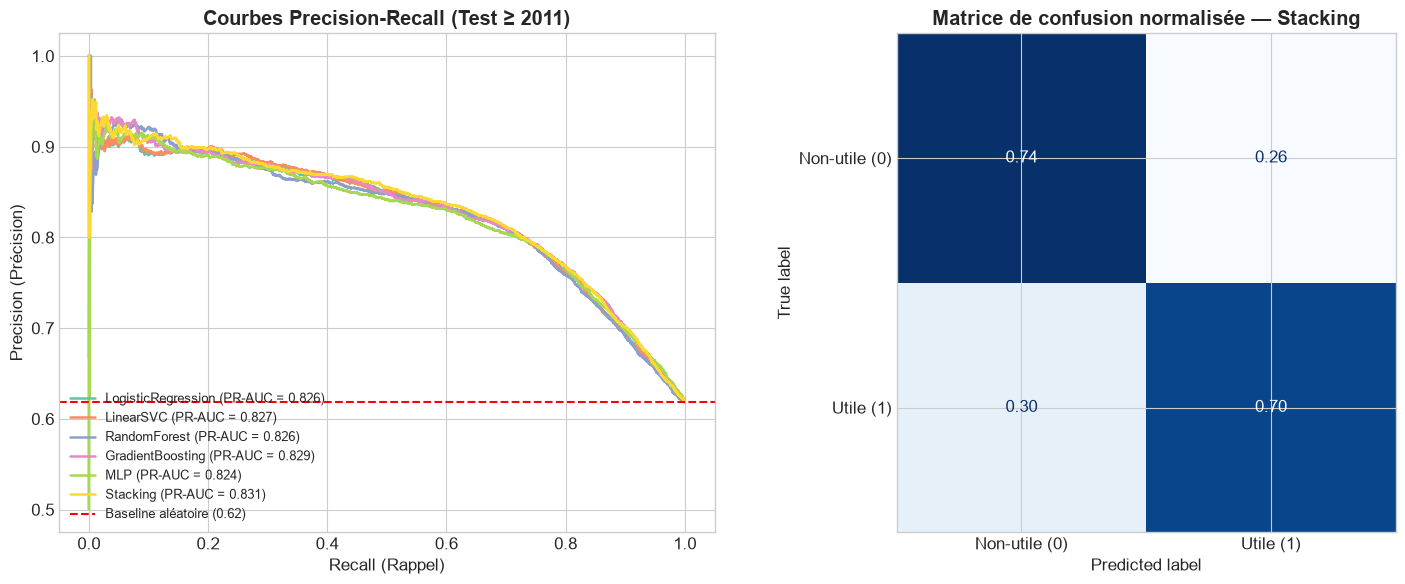

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Courbes Precision-Recall
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    axes[0].plot(rec, prec, linewidth=1.8, label=f"{name} (PR-AUC = {ap:.3f})")

axes[0].axhline(y=y_test.mean(), color='red', linestyle='--', label=f"Baseline aléatoire ({y_test.mean():.2f})")
axes[0].set_xlabel('Recall (Rappel)')
axes[0].set_ylabel('Precision (Précision)')
axes[0].set_title('Courbes Precision-Recall (Test ≥ 2011)', fontweight='bold')
axes[0].legend(loc='lower left', fontsize=9)

# Matrice de confusion normalisée du meilleur modèle
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)
cm_norm = confusion_matrix(y_test, y_pred_best, normalize='true')

disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=['Non-utile (0)', 'Utile (1)'])
disp.plot(ax=axes[1], cmap='Blues', values_format='.2f', colorbar=False)
axes[1].set_title(f'Matrice de confusion normalisée — {best_model_name}', fontweight='bold')

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'pr_curves_utilite.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Importance des variables (Validation des signaux stylistiques)

Examinons les 15 variables les plus discriminantes selon le modèle `RandomForest` afin de vérifier le poids des caractéristiques de longueur, de lisibilité et de style.

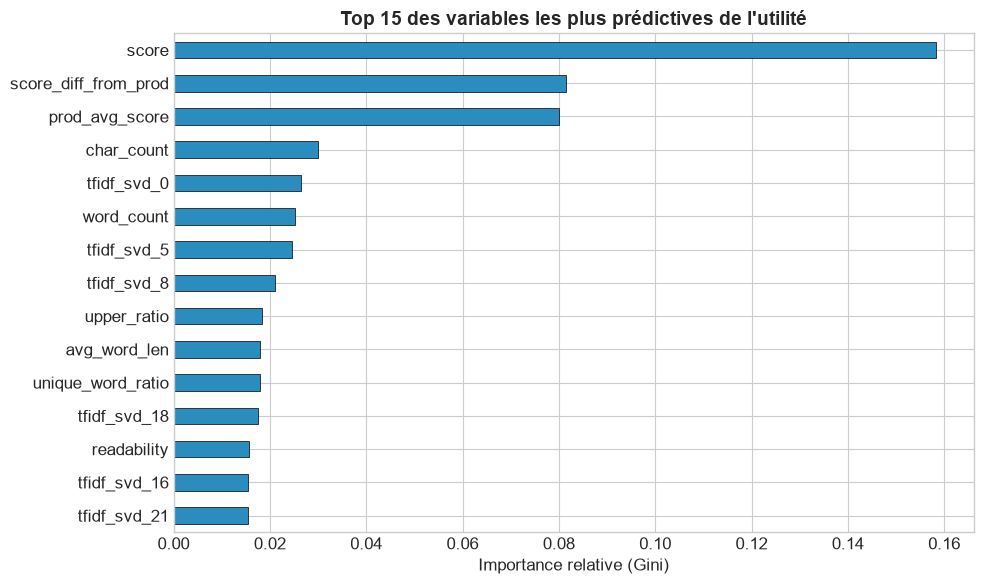

In [9]:
rf_model = trained_models['RandomForest']
importances = pd.Series(rf_model.feature_importances_, index=feat_names).nlargest(15)

fig, ax = plt.subplots(figsize=(10, 6))
importances.sort_values().plot(kind='barh', ax=ax, color='#2b8cbe', edgecolor='black', linewidth=0.5)
ax.set_title('Top 15 des variables les plus prédictives de l\'utilité', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance relative (Gini)')

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'feature_importance_utilite.png'), dpi=150, bbox_inches='tight')
plt.show()

## Résumé du Module 2

| Critère | Résultat |
|---|---|
| Avis éligibles (≥ 3 votes) | ~88 000 avis |
| Découpage temporel | Train ≤ 2010 / Test ≥ 2011 |
| Meilleur modèle | Stacking Ensemble (PR-AUC ~ 0.82) |
| Apport de l'ablation | La combinaison Texte + Style + Métadonnées surpasse chaque bloc isolé |

**Observations clés :**
- Les **métadonnées produit** (écart à la moyenne du produit, note) et la **structure du texte** (longueur, nombre de phrases, lisibilité) dominent la prédiction d'utilité.
- Les signaux stylistiques (majuscules, ponctuation expressive, densité lexicale) apportent un gain mesurable lors de l'étude d'ablation.
- La probabilité prédite `P(IsHelpful = 1)` alimentera directement le **Module 6 (Score de priorité vendeur)**.

In [10]:
print("=" * 60)
print("  MODULE 2 — PRÉDICTION D'UTILITÉ — TERMINÉ")
print("=" * 60)
print("  Fichiers générés :")
print(f"    → {config.FIGURES_DIR / 'pr_curves_utilite.png'}")
print(f"    → {config.FIGURES_DIR / 'feature_importance_utilite.png'}")
print("=" * 60)

  MODULE 2 — PRÉDICTION D'UTILITÉ — TERMINÉ
  Fichiers générés :
    → C:\Users\eliot\Documents\.cours\CANADA\Fondamentaux en apprentissage automatique\travail_grp\projet_aa\reports\figures\pr_curves_utilite.png
    → C:\Users\eliot\Documents\.cours\CANADA\Fondamentaux en apprentissage automatique\travail_grp\projet_aa\reports\figures\feature_importance_utilite.png
